### waveform feature table

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

from allensdk.brain_observatory.ecephys.ecephys_project_cache import (
    EcephysProjectCache
)

base_dir = Path("/Volumes/WD_BLACK/Spikes2Slope")
cache_dir = base_dir / "allen_visual_coding_data"
results_dir = base_dir / "opto_results"

cache = EcephysProjectCache.from_warehouse(
    manifest=str(cache_dir / "manifest.json")
)

units = cache.get_units().rename_axis("unit_id").reset_index()
opto = pd.read_csv(results_dir / "all_opto_unit_results.csv")

print("Allen QC units:", len(units))
print("Optotagging results:", len(opto))
print("QC-matched tagged candidates:", opto["matched_candidate"].sum())

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Allen QC units: 40010
Optotagging results: 8579
QC-matched tagged candidates: 1127


### master table

In [2]:
waveform_features = [
    "waveform_duration",
    "waveform_halfwidth",
    "waveform_PT_ratio",
    "waveform_repolarization_slope",
    "waveform_recovery_slope",
    "waveform_amplitude",
    "waveform_spread",
    "firing_rate"
]

available = [c for c in waveform_features if c in units.columns]
print("Available features:", available)

unit_columns = [
    "unit_id",
    "ecephys_session_id",
    "ecephys_probe_id",
    "ecephys_structure_acronym",
    "snr",
    "presence_ratio",
    "isi_violations",
    "amplitude_cutoff"
] + available

opto_columns = [
    "unit_id",
    "cre_line",
    "baseline_rate_hz",
    "evoked_rate_hz",
    "response_ratio",
    "candidate_tagged",
    "matched_candidate"
]

master = units[unit_columns].merge(
    opto[opto_columns],
    on="unit_id",
    how="left",
    validate="one_to_one"
)

master["is_opto_candidate"] = (
    master["matched_candidate"].fillna(False).astype(bool)
)

master["cell_type_label"] = np.where(
    master["is_opto_candidate"],
    master["cre_line"],
    "unknown"
)

print("Total units:", len(master))
print(master["cell_type_label"].value_counts())

display(master.head())

Available features: ['waveform_duration', 'waveform_halfwidth', 'waveform_PT_ratio', 'waveform_repolarization_slope', 'waveform_recovery_slope', 'waveform_amplitude', 'waveform_spread', 'firing_rate']
Total units: 40010
unknown    38883
Sst          535
Pvalb        345
Vip          247
Name: cell_type_label, dtype: int64


,unit_id,ecephys_session_id,ecephys_probe_id,ecephys_structure_acronym,snr,presence_ratio,isi_violations,amplitude_cutoff,waveform_duration,waveform_halfwidth,...,waveform_spread,firing_rate,cre_line,baseline_rate_hz,evoked_rate_hz,response_ratio,candidate_tagged,matched_candidate,is_opto_candidate,cell_type_label
0,915956282,732592105,733744647,grey,1.911839,0.99,0.104910,0.072728,0.535678,0.164824,...,30.0,6.519432,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
1,915956340,732592105,733744647,grey,3.357908,0.99,0.006825,0.000881,0.563149,0.206030,...,30.0,9.660554,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
2,915956345,732592105,733744647,grey,3.362198,0.99,0.044936,0.001703,0.521943,0.192295,...,30.0,12.698430,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
3,915956349,732592105,733744647,grey,2.684636,0.99,0.120715,0.096378,0.508208,0.192295,...,40.0,16.192413,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
4,915956356,732592105,733744647,grey,2.605408,0.99,0.430427,0.054706,0.549414,0.233501,...,60.0,2.193113,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown


In [3]:
output_path = results_dir / "master_waveform_features.csv"

assert master["unit_id"].is_unique
assert len(master) == len(units)

master.to_csv(output_path, index=False)

tagged = master[master["is_opto_candidate"]].copy()

print("Saved to:", output_path)
print("\nLabeled units by interneuron class:")
print(tagged["cell_type_label"].value_counts())

print("\nMissing waveform features:")
display(tagged[available].isna().sum())

display(
    tagged.groupby("cell_type_label")[available]
    .median()
    .round(3)
)

Saved to: /Volumes/WD_BLACK/Spikes2Slope/opto_results/master_waveform_features.csv

Labeled units by interneuron class:
Sst      535
Pvalb    345
Vip      247
Name: cell_type_label, dtype: int64

Missing waveform features:


waveform_duration                 0
waveform_halfwidth               16
waveform_PT_ratio                 0
waveform_repolarization_slope     0
waveform_recovery_slope          16
waveform_amplitude                0
waveform_spread                   0
firing_rate                       0
dtype: int64

,waveform_duration,waveform_halfwidth,waveform_PT_ratio,waveform_repolarization_slope,waveform_recovery_slope,waveform_amplitude,waveform_spread,firing_rate
cell_type_label,,,,,,,,
Pvalb,0.426,0.179,0.511,0.374,-0.068,113.390,80.0,7.087
Sst,0.604,0.206,0.485,0.340,-0.056,115.310,70.0,4.445
Vip,0.632,0.192,0.466,0.405,-0.058,136.897,70.0,3.654


In [9]:
print("Candidates by putative class:")
display(tagged["cell_type_label"].value_counts())

print("\nCandidates and recording groups by class:")
class_coverage = (
    tagged.groupby("cell_type_label")
    .agg(
        n_units=("unit_id", "nunique"),
        n_sessions=("ecephys_session_id", "nunique"),
    )
)
display(class_coverage)

print("\nCandidate counts by session and class:")
session_counts = (
    tagged.groupby(["ecephys_session_id", "cell_type_label"])
    .size()
    .unstack(fill_value=0)
)
display(session_counts)

print("\nMissing feature values:")
display(tagged[available].isna().sum())


Candidates by putative class:


Sst      535
Pvalb    345
Vip      247
Name: cell_type_label, dtype: int64


Candidates and recording groups by class:


,n_units,n_sessions
cell_type_label,,
Pvalb,345,8
Sst,535,12
Vip,247,8



Candidate counts by session and class:


cell_type_label,Pvalb,Sst,Vip
ecephys_session_id,,,
715093703,0,55,0
719161530,0,41,0
721123822,22,0,0
746083955,32,0,0
751348571,0,0,44
755434585,0,0,58
756029989,0,66,0
758798717,0,32,0
760345702,49,0,0



Missing feature values:


waveform_duration                 0
waveform_halfwidth               16
waveform_PT_ratio                 0
waveform_repolarization_slope     0
waveform_recovery_slope          16
waveform_amplitude                0
waveform_spread                   0
firing_rate                       0
dtype: int64

### visualize waveform correspondence

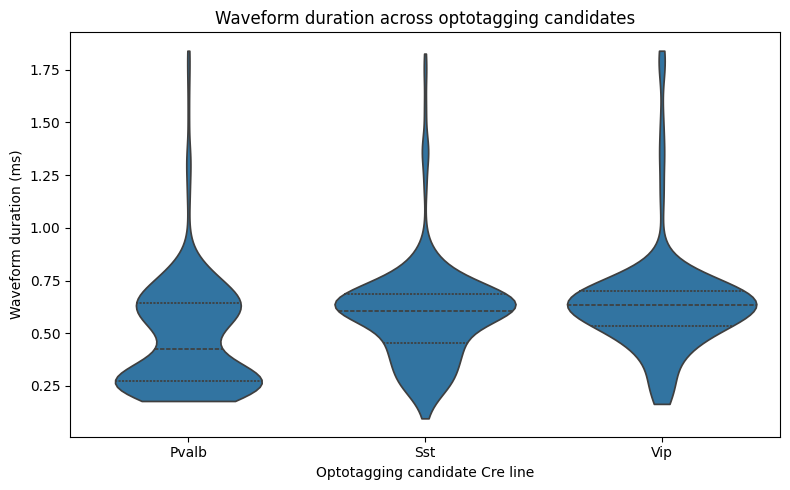

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

order = ["Pvalb", "Sst", "Vip"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=tagged,
    x="cell_type_label",
    y="waveform_duration",
    order=order,
    inner="quartile",
    cut=0,
    ax=ax
)

ax.set(
    xlabel="Optotagging candidate Cre line",
    ylabel="Waveform duration (ms)",
    title="Waveform duration across optotagging candidates"
)

plt.tight_layout()
plt.show()


# validate polarity

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

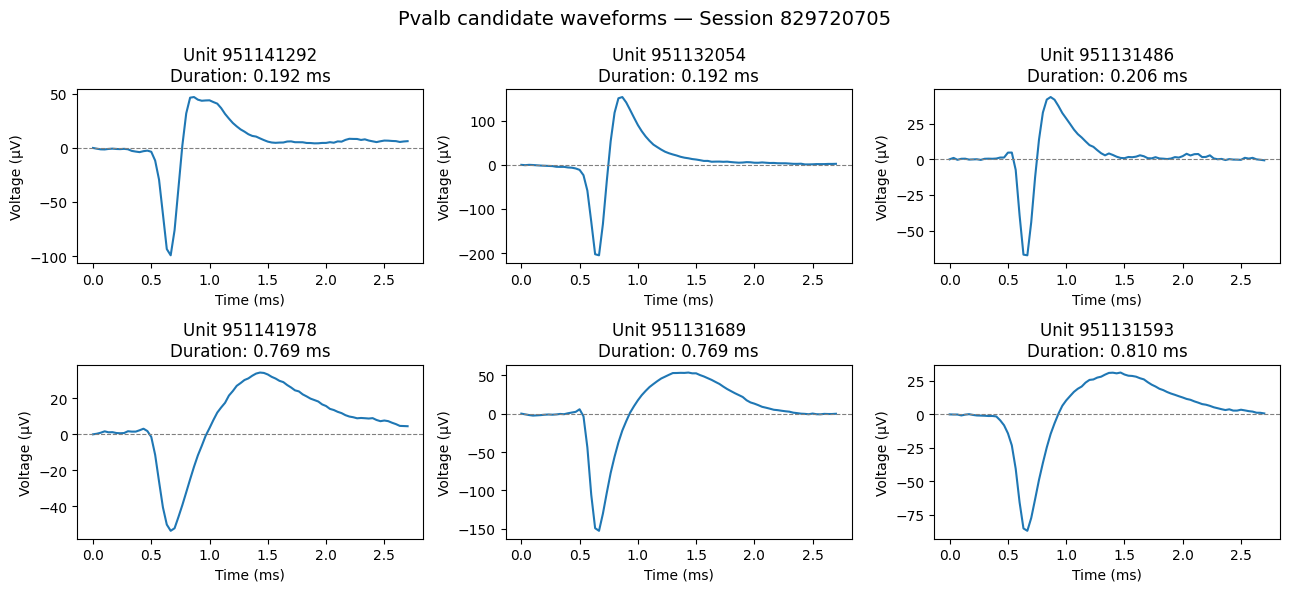

In [11]:
session_id = 829720705
session = cache.get_session_data(session_id)

subset = tagged.loc[
    (tagged["ecephys_session_id"] == session_id)
    & (tagged["cell_type_label"] == "Pvalb")
].sort_values("waveform_duration")

selected = pd.concat([subset.head(3), subset.tail(3)])

fig, axes = plt.subplots(2, 3, figsize=(13, 6))

for ax, (_, unit) in zip(axes.flat, selected.iterrows()):
    unit_id = int(unit["unit_id"])
    waveform = session.mean_waveforms[unit_id]

    peak_channel = int(session.units.loc[unit_id, "peak_channel_id"])

    trace = waveform.sel(channel_id=peak_channel)

    time_ms = trace["time"].values * 1000
    voltage = trace.values

    ax.plot(time_ms, voltage)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    ax.set_title(
        f"Unit {unit_id}\n"
        f"Duration: {unit['waveform_duration']:.3f} ms"
    )
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Voltage (µV)")

fig.suptitle(
    "Pvalb candidate waveforms — Session 829720705",
    fontsize=14
)

plt.tight_layout()
plt.show()


### pv optical response

In [12]:

response_columns = [
    "unit_id",
    "waveform_duration",
    "baseline_rate_hz",
    "evoked_rate_hz",
    "response_ratio",
    "snr",
]

comparison = selected[response_columns].copy()

comparison["waveform_group"] = (
    ["narrow"] * 3 + ["broad"] * 3
)

display(
    comparison[
        ["waveform_group"] + response_columns
    ].round(3)
)


,waveform_group,unit_id,waveform_duration,baseline_rate_hz,evoked_rate_hz,response_ratio,snr
21814,narrow,951141292,0.192,20.000,133.333,6.349,2.879
20616,narrow,951132054,0.192,35.000,198.333,5.509,5.577
20537,narrow,951131486,0.206,3.333,43.333,10.000,2.153
21771,broad,951141978,0.769,0.000,11.667,11.667,2.010
20594,broad,951131689,0.769,0.000,15.000,15.000,3.401
20575,broad,951131593,0.810,0.000,3.333,3.333,3.045


### pulse-by-pulse reliability

In [13]:

epochs = session.optogenetic_stimulation_epochs

pulses = epochs.loc[
    (epochs["stimulus_name"] == "pulse")
    & epochs["duration"].between(
        0.009, 0.020, inclusive="neither"
    )
]

starts = pulses["start_time"].to_numpy()

results = []

for _, unit in selected.iterrows():
    unit_id = int(unit["unit_id"])
    spikes = np.asarray(session.spike_times[unit_id])

    evoked_counts = (
        np.searchsorted(spikes, starts + 0.009)
        - np.searchsorted(spikes, starts + 0.001)
    )

    results.append({
        "unit_id": unit_id,
        "waveform_duration": unit["waveform_duration"],
        "evoked_spikes": int(evoked_counts.sum()),
        "responsive_pulses": int((evoked_counts > 0).sum()),
        "n_pulses": len(starts),
        "response_reliability": np.mean(evoked_counts > 0)
    })

reliability_comparison = pd.DataFrame(results)

display(reliability_comparison.round(3))


/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

,unit_id,waveform_duration,evoked_spikes,responsive_pulses,n_pulses,response_reliability
0,951141292,0.192,80,53,75,0.707
1,951132054,0.192,119,60,75,0.800
2,951131486,0.206,26,20,75,0.267
3,951141978,0.769,7,6,75,0.080
4,951131689,0.769,9,9,75,0.120
5,951131593,0.810,2,2,75,0.027


### event-aligned spike rasters pv candidates

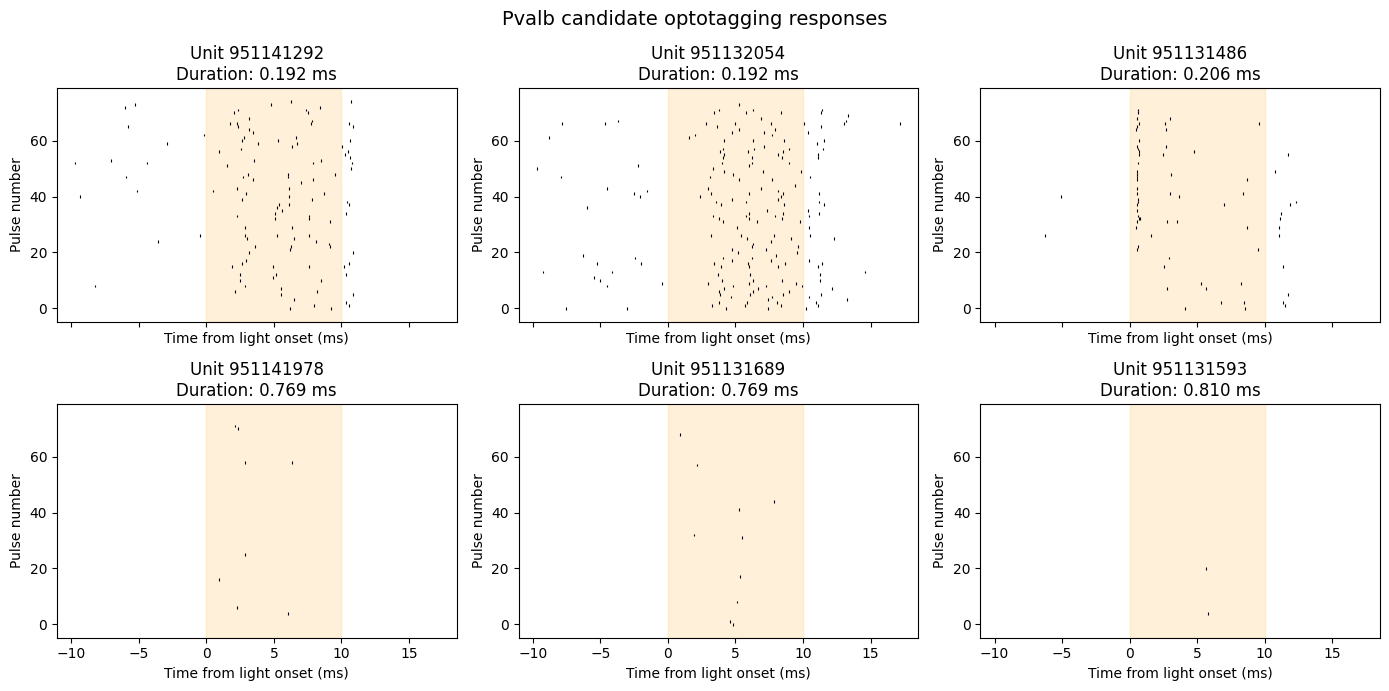

In [14]:

window = (-0.010, 0.025)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)

for ax, (_, unit) in zip(axes.flat, selected.iterrows()):
    unit_id = int(unit["unit_id"])
    spikes = np.asarray(session.spike_times[unit_id])

    aligned_spikes = []

    for onset in starts:
        left = np.searchsorted(spikes, onset + window[0])
        right = np.searchsorted(spikes, onset + window[1])

        aligned_spikes.append(
            (spikes[left:right] - onset) * 1000
        )

    ax.eventplot(
        aligned_spikes,
        colors="black",
        linewidths=0.8
    )

    # Nominal 10 ms pulse interval.
    ax.axvspan(0, 10, color="orange", alpha=0.15)

    ax.set_title(
        f"Unit {unit_id}\n"
        f"Duration: {unit['waveform_duration']:.3f} ms"
    )
    ax.set_xlabel("Time from light onset (ms)")
    ax.set_ylabel("Pulse number")

fig.suptitle("Pvalb candidate optotagging responses", fontsize=14)
plt.tight_layout()
plt.show()
